# What Makes Great Coffee? Quality Drivers for a Honduran Coffee Cooperative

**Google Data Analytics Capstone** · Author: Marzell
*The client (Cooperativa Cafetalera Hondureña) is fictional; the data is real and public (Coffee Quality Institute).*

This notebook covers the Python part of the project:

1. **Setup** — libraries and data
2. **Process (stage 2)** — parsing free-text fields that are hard to clean in SQL: harvest year and altitude
3. **Analyze** — statistics and charts for the guiding questions (Q1–Q5 and the Honduras trend)
4. **Export for Tableau** — files that feed the dashboard

Upstream steps (loading, exploration and structural cleaning) were done in BigQuery: see `sql/01_exploration.sql`, `sql/02_cleaning.sql` and `docs/03_process_changelog.md` in the [GitHub repository](https://github.com/cribas2710/coffee-quality-case-study), which also holds the full documentation, the Tableau dashboard link and the board presentation.

## 1. Setup

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)

# File locations: the same notebook runs in the GitHub repository and on Kaggle
KAGGLE_INPUT = Path("/kaggle/input")
if KAGGLE_INPUT.exists():
    DATA_INTERIM = next(KAGGLE_INPUT.rglob("arabica_stage.csv")).parent   # uploaded dataset (read-only)
    DATA_CLEAN = VISUALS = Path("/kaggle/working")                         # outputs
else:
    DATA_INTERIM = Path("../data/interim")
    DATA_CLEAN = Path("../data/clean")
    VISUALS = Path("../visuals")

### 1.1 Load the staged data

`arabica_stage.csv` was exported from the BigQuery table `coffee_quality.arabica_stage` (output of `02_cleaning.sql`).

By default pandas silently converts strings such as `"n/a"`, `"NA"` or `"None"` into missing values. Here we turn that off and treat **only empty cells** as missing, so every conversion to missing is an explicit, documented decision.

In [2]:
stage = pd.read_csv(
    DATA_INTERIM / "arabica_stage.csv",
    keep_default_na=False,   # do not guess missing values
    na_values=[""],          # only empty cells are missing
    parse_dates=["grading_date"],
)

print(stage.shape)
stage.head(3)

(1311, 36)


,sample_id,source_row_index,region,owner,producer,farm_name,mill,company,in_country_partner,altitude_raw,harvest_year_raw,grading_date,aroma,flavor,aftertaste,acidity,body,balance,uniformity,clean_cup,sweetness,cupper_points,total_cup_points,cat1_defects,cat2_defects,quakers,country,country_recovered,processing_method,variety,color,moisture_pct,moisture_flag,grading_year,is_specialty,total_defects
0,1,0,GUJI-HAMBELA/GOYO,metad plc,METAD PLC,METAD PLC,METAD PLC,METAD Agricultural Developmet plc,METAD Agricultural Development plc,1950-2200,2014,2015-04-04,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,8.75,90.58,0,0,0.0,Ethiopia,False,Washed,Unknown,Green,12.0,ok,2015,True,0
1,2,1,GUJI-HAMBELA/ALAKA,metad plc,METAD PLC,METAD PLC,METAD PLC,METAD Agricultural Developmet plc,METAD Agricultural Development plc,1950-2200,2014,2015-04-04,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,8.58,89.92,0,1,0.0,Ethiopia,False,Washed,Other,Green,12.0,ok,2015,True,1
2,3,2,NaN,Grounds for Health Admin,NaN,"San Marcos Barrancas ""San Cristobal Cuch",NaN,NaN,Specialty Coffee Association,1600 - 1800 m,NaN,2010-05-31,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,9.25,89.75,0,0,0.0,Guatemala,False,Unknown,Bourbon,Unknown,NaN,missing,2010,True,0


In [3]:
# Sanity checks against the SQL validation (V1, V2)
assert len(stage) == 1311
assert stage["sample_id"].is_unique
assert (stage["country"] == "Honduras").sum() == 52
print("Stage data matches the BigQuery validation ✅")

Stage data matches the BigQuery validation ✅


## 2. Process — stage 2: free-text fields

### 2.1 Harvest year

Exploration (F23) found 25 formats in `harvest_year_raw`. The parsing rules, in order:

| Rule | Example | Result |
|---|---|---|
| 1. Take the **first 4-digit year** (a season is named after the year it starts) | `2015/2016`, `March 2010`, `4T72010` | 2015, 2010, 2010 |
| 2. Otherwise take the first **2-digit year** → 20xx | `4T/10`, `08/09 crop` | 2010, 2008 |
| 3. Anything else is missing | `Mayo a Julio`, `TEST`, `mmm` | NaN |
| 4. Reject years outside the data's plausible range (2005–2018) | — | NaN |

In [4]:
def parse_harvest_year(value):
    """Return the harvest year as an int, or NaN if it cannot be determined."""
    if pd.isna(value):
        return np.nan
    text = str(value)

    # Rule 1: first 4-digit year (19xx or 20xx)
    match = re.search(r"(?:19|20)\d{2}", text)
    if match:
        year = int(match.group())
    else:
        # Rule 2: first 2-digit number not followed by another digit -> 20xx
        match = re.search(r"(?<!\d)(\d{2})(?!\d)", text)
        if not match:
            return np.nan          # Rule 3
        year = 2000 + int(match.group(1))

    # Rule 4: plausible range
    return year if 2005 <= year <= 2018 else np.nan

**Unit tests.** Each tricky format found in the exploration becomes a test case. If a rule is changed later and breaks one of these cases, the cell fails immediately.

In [5]:
test_cases = {
    "2012": 2012,
    "2015/2016": 2015,
    "2017 / 2018": 2017,
    "2009-2010": 2009,
    "4T/10": 2010,
    "4T72010": 2010,
    "08/09 crop": 2008,
    "March 2010": 2010,
    "Sept 2009 - April 2010": 2009,
    "Spring 2011 in Colombia.": 2011,
    "Mayo a Julio": np.nan,
    "TEST": np.nan,
    "mmm": np.nan,
    np.nan: np.nan,
}

for raw, expected in test_cases.items():
    result = parse_harvest_year(raw)
    ok = (pd.isna(result) and pd.isna(expected)) or result == expected
    assert ok, f"{raw!r}: expected {expected}, got {result}"
print(f"All {len(test_cases)} harvest-year test cases pass ✅")

All 14 harvest-year test cases pass ✅


In [6]:
stage["harvest_year"] = stage["harvest_year_raw"].apply(parse_harvest_year).astype("Int64")

print("Missing before:", stage["harvest_year_raw"].isna().sum())
print("Missing after: ", stage["harvest_year"].isna().sum())

# Which raw values became missing? (should only be month names / junk)
stage.loc[stage["harvest_year"].isna() & stage["harvest_year_raw"].notna(), "harvest_year_raw"].value_counts()

Missing before: 47
Missing after:  58


harvest_year_raw
Mayo a Julio             3
TEST                     2
Abril - Julio            2
May-August               1
mmm                      1
January Through April    1
August to December       1
Name: count, dtype: int64

**Consistency check.** Coffee is graded after it is harvested, so the harvest year should not be later than the grading year. A harvest year 1 year earlier is normal (harvest in one season, grading the next).

In [7]:
gap = stage["grading_year"] - stage["harvest_year"]
gap.value_counts(dropna=False).sort_index()

-1        2
0       906
1       334
2        11
<NA>     58
Name: count, dtype: Int64

Two samples have a harvest year **later** than their grading year (Brazil, harvest 2016 vs. graded 2015-12-28). Coffee cannot be graded before it is harvested, so these two values are set to missing; the rows are kept (changelog step 25).

In [8]:
impossible = stage["harvest_year"] > stage["grading_year"]
print(stage.loc[impossible, ["sample_id", "country", "harvest_year_raw", "grading_date"]])

stage.loc[impossible, "harvest_year"] = pd.NA
print("Valid harvest years:", stage["harvest_year"].notna().sum())

      sample_id country harvest_year_raw grading_date
637         638  Brazil             2016   2015-12-28
1292       1293  Brazil             2016   2015-12-28
Valid harvest years: 1251


### 2.2 Altitude

Exploration (F24, F25) found 123 formats in `altitude_raw`: plain numbers, meters in several languages (`msnm`, `MASL`, `metros`, `公尺`), feet (`ft`, `PSNM` = *pies sobre el nivel del mar*), ranges and different thousands separators. The parsing rules, in order:

| Rule | Example | Result |
|---|---|---|
| 1. Empty → `missing` | — | NaN |
| 2. Read numbers with any thousands separator (`,` `.` `'`); a letter O typed as a zero is fixed | `1,700` · `1.872` · `1'500` · `12OO` | 1700 · 1872 · 1500 · 1200 |
| 3. Two numbers joined by a range word (`-`, `~`, `a`, `to`, `thru`, `and`) → **midpoint** | `1600 - 1800 m`, `De 1.600 a 1.950 msnm` | 1700, 1775 |
| 4. Two numbers without a range word → first number; joined by `/` → ambiguous | `1,800 meters (5,900` · `100/2000` | 1800 · `invalid` |
| 5. A decimal below 10 is written in thousands | `1.2`, `1.65` | 1200, 1650 |
| 6. Explicit feet keyword → × 0.3048 (`feet`) | `5000 ft`, `4000 PSNM`, `5000 Pies` | 1524, 1219, 1524 |
| 7. No feet keyword but above 3,000 → impossible in meters, assume feet (`assumed_feet`) | `5000`, `5500 METROS` | 1524, 1676 |
| 8. Outside 100–3,000 m after conversion, or no number → `invalid` | `1`, `50`, `TEST`, `190164` | NaN |

In [9]:
FEET_TO_M = 0.3048
NUMBER = re.compile(r"\d+(?:[,.']\d{3})*(?:\.\d+)?")
FEET_WORDS = re.compile(r"ft|feet|pies|p\.?\s?s\.?\s?n|\d\s*f\b")
RANGE_WORDS = re.compile(r"-|~|\ba\b|\bto\b|\bthru\b|\band\b")


def to_number(token):
    """Convert '1,700', '1.872', "1'500" or '1901.64' to a float."""
    token = token.replace(",", "").replace("'", "")
    if re.fullmatch(r"\d+\.\d{3}", token):   # dot used as thousands separator
        token = token.replace(".", "")
    return float(token)


def parse_altitude(value):
    """Return (altitude in meters, flag) for a free-text altitude."""
    if pd.isna(value):
        return np.nan, "missing"                                   # Rule 1
    text = str(value).lower()
    text = re.sub(r"(?<=\d)o+", lambda m: "0" * len(m.group()), text)  # Rule 2: 12OO -> 1200

    numbers = list(NUMBER.finditer(text))
    if not numbers:
        return np.nan, "invalid"                                   # Rule 8
    first = numbers[0]
    meters = to_number(first.group())

    if len(numbers) >= 2:
        between = text[first.end():numbers[1].start()]
        if "/" in between:
            return np.nan, "invalid"                               # Rule 4: ambiguous
        if RANGE_WORDS.search(between):
            meters = (meters + to_number(numbers[1].group())) / 2  # Rule 3: midpoint

    if meters < 10 and "." in first.group():
        meters *= 1000                                             # Rule 5

    if FEET_WORDS.search(text):
        meters, flag = meters * FEET_TO_M, "feet"                  # Rule 6
    elif meters > 3000:
        meters, flag = meters * FEET_TO_M, "assumed_feet"          # Rule 7
    else:
        flag = "meters"

    if not 100 <= meters <= 3000:
        return np.nan, "invalid"                                   # Rule 8
    return round(meters), flag

**Unit tests.** As with harvest year, every tricky format from the exploration is a test case.

In [10]:
test_cases = {
    "1950-2200": (2075, "meters"),
    "1600 - 1800 m": (1700, "meters"),
    "Meters above sea level: 1.872": (1872, "meters"),
    "De 1.600 a 1.950 msnm": (1775, "meters"),
    "1200m to 1350m": (1275, "meters"),
    "Between 700 and 1,400 meters": (1050, "meters"),
    "approx. 1'500 metres a.s.l.": (1500, "meters"),
    "1,800 meters (5,900": (1800, "meters"),
    "12OO": (1200, "meters"),
    "1.65": (1650, "meters"),
    "950公尺": (950, "meters"),
    "800++": (800, "meters"),
    "5000 FT.": (1524, "feet"),
    "4000 P.S.N.M.": (1219, "feet"),
    "3,500 - 5,200 feet": (1326, "feet"),
    "5000 Pies": (1524, "feet"),
    "3280": (1000, "assumed_feet"),
    "5440 - 5760 METROS": (1707, "assumed_feet"),
    "100/2000": (np.nan, "invalid"),
    "190164": (np.nan, "invalid"),
    np.nan: (np.nan, "missing"),
}

for raw, (expected_m, expected_flag) in test_cases.items():
    result_m, result_flag = parse_altitude(raw)
    ok = ((pd.isna(result_m) and pd.isna(expected_m)) or result_m == expected_m) and result_flag == expected_flag
    assert ok, f"{raw!r}: expected {(expected_m, expected_flag)}, got {(result_m, result_flag)}"
print(f"All {len(test_cases)} altitude test cases pass ✅")

All 21 altitude test cases pass ✅


In [11]:
parsed = stage["altitude_raw"].apply(parse_altitude)
stage["altitude_m"] = parsed.str[0].astype("Int64")
stage["altitude_flag"] = parsed.str[1]

stage["altitude_flag"].value_counts()

altitude_flag
meters          948
missing         217
assumed_feet     71
feet             47
invalid          28
Name: count, dtype: int64

**Invalid values worth a second look.** Most `invalid` values are junk (`TEST`, `mmm`, `none`) or clearly not an altitude (`1`, `50`). Three can be recovered **with evidence** (changelog step 30); the rest stay missing:

| sample_id | Raw value | Evidence | Recovered |
|---|---|---|---|
| 897 | `190164` | The same owner and farm report `1901.64` in other samples: the decimal point was lost | 1,902 m |
| 444 | `16.8` | Single-typo fix (`1680`), consistent with the known altitude of Moshi (Kilimanjaro, Tanzania) | 1,680 m |
| 544 | `11000 metros` | Single-typo fix (`1100`), consistent with the known altitude of Cerrado (Brazil) | 1,100 m |

In [12]:
stage.loc[stage["altitude_flag"] == "invalid", ["sample_id", "country", "region", "altitude_raw"]]

,sample_id,country,region,altitude_raw
100,101,Kenya,NaN,-1
169,170,Brazil,mmm,mmm
170,171,Brazil,TEST,TEST
254,255,Thailand,Thailand,-
265,266,Taiwan,台灣,none
279,280,Brazil,South of Minas Gerais,1
443,444,Tanzania,Moshi,16.8
458,459,Colombia,unkown,unkown
482,483,Brazil,South of Minas Gerais,1
543,544,Brazil,Cerrado,11000 metros


In [13]:
# Evidence for sample 897: same owner and farm, other samples
farm_897 = stage.loc[stage["sample_id"] == 897, ["owner", "farm_name"]].iloc[0]
print(stage.loc[(stage["owner"] == farm_897["owner"]) & (stage["farm_name"] == farm_897["farm_name"]),
                ["sample_id", "altitude_raw"]].drop_duplicates("altitude_raw"))

recovered = {897: 1902, 444: 1680, 544: 1100}
is_recovered = stage["sample_id"].isin(recovered.keys())
stage.loc[is_recovered, "altitude_m"] = stage.loc[is_recovered, "sample_id"].map(recovered)
stage.loc[is_recovered, "altitude_flag"] = "recovered"

stage["altitude_flag"].value_counts()

      sample_id altitude_raw
356         357         4000
815         816         1901
896         897       190164
1144       1145      1901.64


altitude_flag
meters          948
missing         217
assumed_feet     71
feet             47
invalid          25
recovered         3
Name: count, dtype: int64

### 2.3 Result checks

In [14]:
valid = stage["altitude_m"].notna()
print(f"Altitude available: {valid.sum():,} of {len(stage):,} ({valid.mean():.1%})")
print(f"Median {stage['altitude_m'].median():,.0f} m, range {stage['altitude_m'].min():,}–{stage['altitude_m'].max():,} m")

honduras = stage[stage["country"] == "Honduras"]
print(f"Honduras: {honduras['altitude_m'].notna().sum()} of {len(honduras)} samples, "
      f"{honduras['altitude_m'].min():,}–{honduras['altitude_m'].max():,} m, median {honduras['altitude_m'].median():,.0f} m")

# Must match the BigQuery validation of the final table (V5)
assert valid.sum() == 1069
assert stage["altitude_m"].dropna().between(100, 3000).all()
assert stage["harvest_year"].notna().sum() == 1251

Altitude available: 1,069 of 1,311 (81.5%)
Median 1,311 m, range 100–2,560 m
Honduras: 50 of 52 samples, 1,200–1,650 m, median 1,400 m


### 2.4 Export the clean dataset

The raw text fields are dropped (their parsed versions replace them) and the columns are reordered so related fields sit together. This file is uploaded to BigQuery as `coffee_quality.arabica_clean`.

In [15]:
clean_columns = [
    "sample_id", "source_row_index", "grading_date", "grading_year",
    "country", "country_recovered", "region", "altitude_m", "altitude_flag",
    "owner", "producer", "farm_name", "mill", "company", "in_country_partner",
    "harvest_year", "variety", "processing_method",
    "aroma", "flavor", "aftertaste", "acidity", "body", "balance",
    "uniformity", "clean_cup", "sweetness", "cupper_points", "total_cup_points", "is_specialty",
    "cat1_defects", "cat2_defects", "quakers", "total_defects",
    "moisture_pct", "moisture_flag", "color",
]
clean = stage[clean_columns]
assert set(stage.columns) - set(clean_columns) == {"altitude_raw", "harvest_year_raw"}

clean.to_csv(DATA_CLEAN / "coffee_arabica_clean.csv", index=False)
print(clean.shape)

(1311, 37)


## 3. Analyze

Country benchmark (Q1) and altitude bands (Q2.1) were computed in BigQuery (`sql/03_analysis.sql`). This section adds what SQL does poorly: **rank correlations with p-values, within-group comparisons and charts**.

### 3.0 Setup for the analysis

In [16]:
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(DATA_CLEAN / "coffee_arabica_clean.csv", parse_dates=["grading_date"])
print(df.shape)

# Chart style: one shared look for every figure in the project
COLOR_MAIN = "#2a78d6"       # all samples / other countries
COLOR_HONDURAS = "#eb6834"   # the client's country, always the same color
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10,
})

(1311, 37)


### 3.1 Q1 · Benchmark (cross-check)

The ranking was built in SQL (Q1.1, Q1.2). Recomputing it here confirms that the CSV used for the charts gives the same numbers as BigQuery.

In [17]:
BENCHMARK = ["Colombia", "Guatemala", "Costa Rica", "Ethiopia", "Brazil"]   # Honduras' competitors

ranking = (df[df["country"] != "Unknown"]
           .groupby("country")["total_cup_points"].agg(["count", "mean", "std"])
           .query("count >= 10")
           .sort_values("mean", ascending=False))
ranking["ci95_low"] = ranking["mean"] - 1.96 * ranking["std"] / np.sqrt(ranking["count"])
ranking["ci95_high"] = ranking["mean"] + 1.96 * ranking["std"] / np.sqrt(ranking["count"])
ranking["rank"] = range(1, len(ranking) + 1)

print(f"Countries ranked: {len(ranking)}; Honduras rank: {ranking.loc['Honduras', 'rank']}")
ranking.loc[BENCHMARK + ["Honduras"]].round(2)

Countries ranked: 19; Honduras rank: 18


,count,mean,std,ci95_low,ci95_high,rank
country,,,,,,
Colombia,190,83.22,1.60,82.99,83.45,4
Guatemala,181,81.85,2.89,81.43,82.27,14
Costa Rica,51,82.79,2.38,82.14,83.44,7
Ethiopia,45,84.54,6.72,82.58,86.51,1
Brazil,132,82.41,2.13,82.04,82.77,11
Honduras,52,80.88,3.56,79.92,81.85,18


### 3.2 Q2 · Altitude

Q2.1 in SQL showed that scores are flat below 1,400 m and rise above it. The chart shows each band's mean with its 95% confidence interval.

In [18]:
alt = df.dropna(subset=["altitude_m"]).copy()
bands = [0, 1000, 1400, 1800, 3001]
labels = ["< 1,000 m", "1,000–1,399 m", "1,400–1,799 m", "≥ 1,800 m"]
alt["altitude_band"] = pd.cut(alt["altitude_m"], bins=bands, labels=labels, right=False)

band_stats = alt.groupby("altitude_band", observed=True)["total_cup_points"].agg(["count", "mean", "std"])
band_stats["ci95"] = 1.96 * band_stats["std"] / np.sqrt(band_stats["count"])
band_stats.round(2)

,count,mean,std,ci95
altitude_band,,,,
"< 1,000 m",159,81.72,2.50,0.39
"1,000–1,399 m",421,81.66,2.69,0.26
"1,400–1,799 m",392,82.58,2.47,0.24
"≥ 1,800 m",97,83.79,2.61,0.52


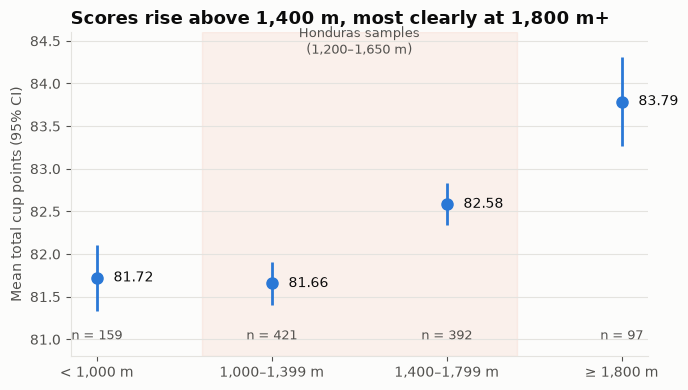

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(band_stats))
ax.errorbar(x, band_stats["mean"], yerr=band_stats["ci95"], fmt="o", color=COLOR_MAIN,
            markersize=8, elinewidth=2, capsize=0)
for xi, (mean, n) in enumerate(zip(band_stats["mean"], band_stats["count"])):
    ax.annotate(f"{mean:.2f}", (xi, mean), xytext=(12, 0), textcoords="offset points",
                va="center", color=TEXT)
    ax.annotate(f"n = {n}", (xi, 81.0), ha="center", color=MUTED, fontsize=9)

ax.axvspan(0.6, 2.4, color=COLOR_HONDURAS, alpha=0.08, zorder=0)
ax.annotate("Honduras samples\n(1,200–1,650 m)", (1.5, 84.35), ha="center", color=MUTED, fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylim(80.8, 84.6)
ax.set_ylabel("Mean total cup points (95% CI)")
ax.set_title("Scores rise above 1,400 m, most clearly at 1,800 m+")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "q2_altitude_bands.png", dpi=200)
plt.show()

**Spearman rank correlation.** Altitude and score are not normally distributed and have outliers, so we use Spearman's ρ instead of Pearson's r: it correlates the *ranks* (1st, 2nd, 3rd…) instead of the raw values. ρ goes from −1 to +1; the p-value is the probability of seeing a correlation this strong if there were no association at all.

In [20]:
rho, p = stats.spearmanr(alt["altitude_m"], alt["total_cup_points"])
print(f"All samples: rho = {rho:.3f}, p = {p:.1e}, n = {len(alt)}")

# Robustness check: only altitudes reported in meters or explicit feet
reported = alt[alt["altitude_flag"].isin(["meters", "feet"])]
rho_r, p_r = stats.spearmanr(reported["altitude_m"], reported["total_cup_points"])
print(f"Without assumed/recovered altitudes: rho = {rho_r:.3f}, p = {p_r:.1e}, n = {len(reported)}")

All samples: rho = 0.280, p = 1.2e-20, n = 1069
Without assumed/recovered altitudes: rho = 0.289, p = 1.3e-20, n = 995


**Is it altitude, or is it the country?** High-altitude samples come mostly from Colombia, Ethiopia, Costa Rica and Kenya, countries that also differ in varieties, processing and know-how. If altitude itself were the driver, we would expect higher farms to score better **within the same country** too.

In [21]:
print("Countries in the ≥ 1,800 m band:")
print(alt.loc[alt["altitude_band"] == "≥ 1,800 m", "country"].value_counts().head(6), "\n")

rows = []
for country, group in alt.groupby("country"):
    if len(group) >= 30 or country == "Honduras":
        r, pval = stats.spearmanr(group["altitude_m"], group["total_cup_points"])
        rows.append({"country": country, "n": len(group), "rho": r, "p_value": pval,
                     "altitude_range_m": f"{int(group['altitude_m'].min()):,}–{int(group['altitude_m'].max()):,}"})
within = pd.DataFrame(rows).sort_values("rho")
within.round(3)

Countries in the ≥ 1,800 m band:
country
Colombia      33
Ethiopia      16
Costa Rica    11
Kenya          9
Guatemala      8
Uganda         7
Name: count, dtype: int64 



,country,n,rho,p_value,altitude_range_m
8,Tanzania,36,-0.083,0.629,"1,317–2,285"
6,Mexico,232,0.025,0.706,"100–1,800"
0,Brazil,94,0.079,0.447,"695–1,300"
1,Colombia,156,0.096,0.234,"175–2,560"
5,Honduras,50,0.103,0.476,"1,200–1,650"
4,Guatemala,156,0.105,0.194,"503–2,100"
2,Costa Rica,46,0.131,0.386,"1,100–1,900"
3,Ethiopia,30,0.359,0.051,"1,494–2,075"
7,Taiwan,69,0.436,0.000,"110–1,300"


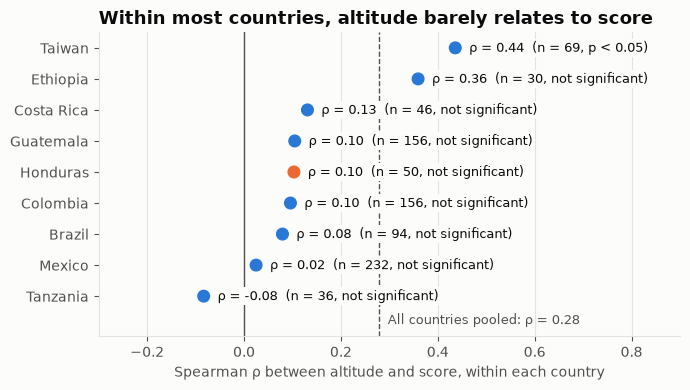

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(within))
colors = [COLOR_HONDURAS if c == "Honduras" else COLOR_MAIN for c in within["country"]]
ax.scatter(within["rho"], y, s=70, color=colors, zorder=3)
ax.axvline(0, color=MUTED, linewidth=1)
ax.axvline(rho, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"All countries pooled: ρ = {rho:.2f}", (rho, -0.9), xytext=(6, 0),
            textcoords="offset points", color=MUTED, fontsize=9)
ax.set_ylim(-1.3, len(within) - 0.5)
for yi, (r, pval, n) in enumerate(zip(within["rho"], within["p_value"], within["n"])):
    label = f"ρ = {r:.2f}  (n = {n}, {'p < 0.05' if pval < 0.05 else 'not significant'})"
    ax.annotate(label, (r, yi), xytext=(10, 0), textcoords="offset points", va="center", fontsize=9,
                bbox=dict(boxstyle="square,pad=0.15", facecolor=SURFACE, edgecolor="none"), zorder=4)
ax.set_yticks(y, within["country"])
ax.set_xlim(-0.3, 0.9)
ax.set_xlabel("Spearman ρ between altitude and score, within each country")
ax.set_title("Within most countries, altitude barely relates to score")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "q2_altitude_within_country.png", dpi=200)
plt.show()

### 3.3 Q3 · Processing method

SQL (Q3.1) showed that methods differ by less than one point. Here we test whether those differences are larger than chance. **Kruskal–Wallis** compares several groups at once without assuming normal distributions (it works on ranks, like Spearman). `Unknown` is excluded because it is not a method.

In [23]:
methods = df[df["processing_method"] != "Unknown"]

method_stats = methods.groupby("processing_method")["total_cup_points"].agg(["count", "mean", "std"])
method_stats["ci95"] = 1.96 * method_stats["std"] / np.sqrt(method_stats["count"])
method_stats = method_stats.sort_values("mean")

for column in ["total_cup_points", "cat1_defects", "cat2_defects"]:
    groups = [g[column] for _, g in methods.groupby("processing_method")]
    print(f"Kruskal–Wallis {column}: p = {stats.kruskal(*groups).pvalue:.3f}")

method_stats.round(2)

Kruskal–Wallis total_cup_points: p = 0.033
Kruskal–Wallis cat1_defects: p = 0.086
Kruskal–Wallis cat2_defects: p = 0.453


,count,mean,std,ci95
processing_method,,,,
Other,26,81.28,4.00,1.54
Washed,812,81.96,2.68,0.18
Natural,251,82.35,2.75,0.34
Semi-washed,56,82.63,1.77,0.46
Honey,14,82.81,1.69,0.88


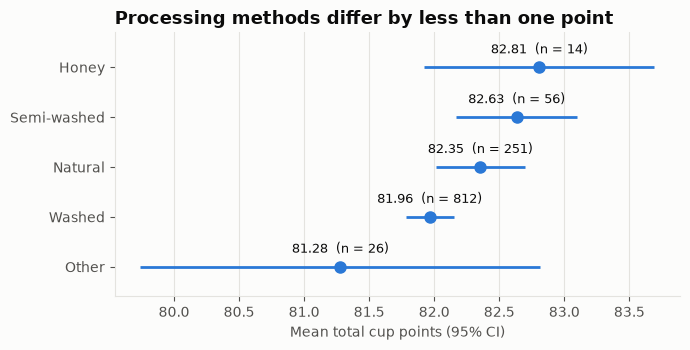

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(method_stats))
ax.errorbar(method_stats["mean"], y, xerr=method_stats["ci95"], fmt="o", color=COLOR_MAIN,
            markersize=8, elinewidth=2, capsize=0)
for yi, (mean, n) in enumerate(zip(method_stats["mean"], method_stats["count"])):
    ax.annotate(f"{mean:.2f}  (n = {n})", (mean, yi), xytext=(0, 10), textcoords="offset points",
                ha="center", color=TEXT, fontsize=9)
ax.set_yticks(y, method_stats.index)
ax.set_ylim(-0.6, len(method_stats) - 0.3)
ax.set_xlabel("Mean total cup points (95% CI)")
ax.set_title("Processing methods differ by less than one point")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "q3_processing_methods.png", dpi=200)
plt.show()

**Is it the method, or the country?** Semi-washed scores above washed, but most semi-washed samples come from a few countries:

In [25]:
df.loc[df["processing_method"] == "Semi-washed", "country"].value_counts(normalize=True).head(3).round(2)

country
Brazil    0.43
Mexico    0.25
Taiwan    0.16
Name: proportion, dtype: float64

To remove the country effect, we compare washed and natural **within each country** that has at least 5 samples of each. The **Mann–Whitney U** test compares two groups by rank; medians are shown because the groups are small and skewed.

In [26]:
rows = []
for country, group in df.groupby("country"):
    washed = group.loc[group["processing_method"] == "Washed", "total_cup_points"]
    natural = group.loc[group["processing_method"] == "Natural", "total_cup_points"]
    if len(washed) >= 5 and len(natural) >= 5:
        rows.append({"country": country, "n_washed": len(washed), "n_natural": len(natural),
                     "median_washed": washed.median(), "median_natural": natural.median(),
                     "p_value": stats.mannwhitneyu(washed, natural).pvalue})
washed_natural = pd.DataFrame(rows)
washed_natural["difference"] = washed_natural["median_natural"] - washed_natural["median_washed"]
washed_natural = washed_natural.sort_values("difference")

print(f"Significant (p < 0.05) in {(washed_natural['p_value'] < 0.05).sum()} of {len(washed_natural)} countries")
washed_natural.round(3)

Significant (p < 0.05) in 1 of 9 countries


,country,n_washed,n_natural,median_washed,median_natural,p_value,difference
2,Ethiopia,8,17,85.625,85.080,0.503,-0.545
4,Honduras,35,14,81.670,81.420,0.816,-0.250
1,Colombia,127,27,83.500,83.420,0.868,-0.080
7,Uganda,18,7,83.790,83.750,0.565,-0.040
8,United States (Hawaii),9,40,82.080,82.165,0.969,0.085
0,Brazil,6,80,81.960,82.330,0.259,0.370
3,Guatemala,161,10,82.330,83.170,0.065,0.840
5,Mexico,198,17,81.500,82.670,0.031,1.170
6,Taiwan,37,13,81.670,82.920,0.298,1.250


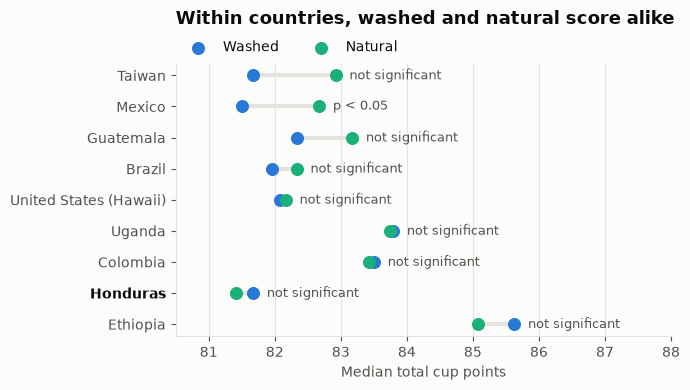

In [27]:
COLOR_NATURAL = "#1baf7a"

fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(washed_natural))
ax.hlines(y, washed_natural["median_washed"], washed_natural["median_natural"], color=GRID, linewidth=3, zorder=1)
ax.scatter(washed_natural["median_washed"], y, s=70, color=COLOR_MAIN, label="Washed", zorder=3)
ax.scatter(washed_natural["median_natural"], y, s=70, color=COLOR_NATURAL, label="Natural", zorder=3)
for yi, (w, n, pval) in enumerate(zip(washed_natural["median_washed"], washed_natural["median_natural"],
                                      washed_natural["p_value"])):
    ax.annotate("p < 0.05" if pval < 0.05 else "not significant", (max(w, n), yi), xytext=(10, 0),
                textcoords="offset points", va="center", color=MUTED, fontsize=9)
ax.set_yticks(y, washed_natural["country"])
for label in ax.get_yticklabels():
    if label.get_text() == "Honduras":
        label.set_fontweight("bold")
        label.set_color(TEXT)
ax.set_xlim(80.5, 88)
ax.set_xlabel("Median total cup points")
ax.set_title("Within countries, washed and natural score alike", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, borderaxespad=0.2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "q3_washed_vs_natural.png", dpi=200)
plt.show()

### 3.4 Q4 · Defects

A **defective cup** is a sample where at least one of the five cups failed: `clean_cup` or `uniformity` below 10 (the pattern of Honduras' low tail in Q1). First, the rank correlation between green-coffee defects and score:

In [28]:
df["has_defective_cup"] = (df["clean_cup"] < 10) | (df["uniformity"] < 10)

for column in ["cat1_defects", "cat2_defects"]:
    r, pval = stats.spearmanr(df[column], df["total_cup_points"])
    print(f"{column}: rho = {r:.2f}, p = {pval:.1e}")

cat1_defects: rho = -0.12, p = 1.3e-05
cat2_defects: rho = -0.17, p = 7.5e-10


**How many points is each defect associated with?** Each bar compares samples with the defect against samples without it (for Category 2: more than 10 defects vs. none).

In [29]:
score = df["total_cup_points"]
defect_gaps = pd.Series({
    "Any Cat. 1 defect": score[df["cat1_defects"] > 0].mean() - score[df["cat1_defects"] == 0].mean(),
    "More than 10 Cat. 2 defects": score[df["cat2_defects"] > 10].mean() - score[df["cat2_defects"] == 0].mean(),
    "At least one defective cup": score[df["has_defective_cup"]].mean() - score[~df["has_defective_cup"]].mean(),
})
defect_gaps.round(2)

Any Cat. 1 defect             -1.13
More than 10 Cat. 2 defects   -2.58
At least one defective cup    -3.77
dtype: float64

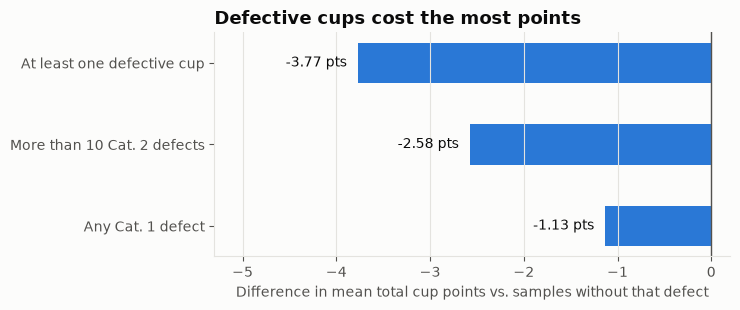

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(defect_gaps))
ax.barh(y, defect_gaps, height=0.5, color=COLOR_MAIN)
for yi, gap in enumerate(defect_gaps):
    ax.annotate(f"{gap:.2f} pts", (gap, yi), xytext=(-8, 0), textcoords="offset points",
                ha="right", va="center", color=TEXT)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, defect_gaps.index)
ax.set_xlim(-5.3, 0.2)
ax.set_xlabel("Difference in mean total cup points vs. samples without that defect")
ax.set_title("Defective cups cost the most points")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "q4_defect_gaps.png", dpi=200)
plt.show()

**Is the cup-defect gap only arithmetic?** `clean_cup`, `uniformity` and `sweetness` are part of the total, so a failed cup lowers the score mechanically. If samples with a defective cup *also* score lower on the 7 quality attributes, the defect is associated with a worse cup overall.

In [31]:
QUALITY_ATTRIBUTES = ["aroma", "flavor", "aftertaste", "acidity", "body", "balance", "cupper_points"]
PER_CUP_ATTRIBUTES = ["clean_cup", "uniformity", "sweetness"]

parts = pd.DataFrame({
    "per_cup_attributes": df[PER_CUP_ATTRIBUTES].sum(axis=1),
    "quality_attributes": df[QUALITY_ATTRIBUTES].sum(axis=1),
}).groupby(df["has_defective_cup"]).mean()
parts.loc["gap"] = parts.loc[True] - parts.loc[False]
parts.round(2)

,per_cup_attributes,quality_attributes
has_defective_cup,,
False,29.98,52.76
True,27.37,51.60
gap,-2.61,-1.16


In [32]:
honduras = df[df["country"] == "Honduras"]
print("Honduras defective-cup samples:")
print(honduras.loc[honduras["has_defective_cup"], ["sample_id", "total_cup_points", "grading_year"]]
      .sort_values("total_cup_points").to_string(index=False))
print(f"\nHonduras mean without them: {honduras.loc[~honduras['has_defective_cup'], 'total_cup_points'].mean():.2f}")

Honduras defective-cup samples:
 sample_id  total_cup_points  grading_year
      1305             69.17          2014
      1306             69.17          2014
      1304             69.33          2014
      1294             73.42          2014
      1272             76.00          2014

Honduras mean without them: 81.89


### 3.5 Q5 · Sensory profile

We focus on the 7 attributes that vary between samples (`uniformity`, `clean_cup` and `sweetness` sit at 10 for most samples, F17). Honduras is compared with the pooled samples of the 5 benchmark competitors using Mann–Whitney. The test is repeated **without defective cups** to check that the gap is not just the 2014 low tail.

In [33]:
bench = df[df["country"].isin(BENCHMARK + ["Honduras"])]
is_honduras = bench["country"] == "Honduras"

rows = []
for attribute in QUALITY_ATTRIBUTES:
    for subset, mask in [("all samples", pd.Series(True, index=bench.index)),
                         ("no defective cups", ~bench["has_defective_cup"])]:
        hn = bench.loc[is_honduras & mask, attribute]
        comp = bench.loc[~is_honduras & mask, attribute]
        rows.append({"attribute": attribute, "subset": subset, "honduras": hn.mean(),
                     "competitors": comp.mean(), "gap": hn.mean() - comp.mean(),
                     "p_value": stats.mannwhitneyu(hn, comp).pvalue})
sensory = pd.DataFrame(rows)
sensory.pivot(index="attribute", columns="subset", values=["gap", "p_value"]).sort_values(("gap", "all samples")).round(4)

gap                       p_value                  
subset        all samples no defective cups all samples no defective cups
attribute                                                                
balance           -0.3095           -0.2440         0.0            0.0000
aftertaste        -0.2619           -0.1989         0.0            0.0000
cupper_points     -0.2486           -0.2001         0.0            0.0000
acidity           -0.2290           -0.1737         0.0            0.0000
flavor            -0.2150           -0.1540         0.0            0.0000
body              -0.1953           -0.1373         0.0            0.0001
aroma             -0.1847           -0.1382         0.0            0.0000

In [34]:
attribute_corr = df[QUALITY_ATTRIBUTES].corr(method="spearman")
pairs = attribute_corr.values[np.triu_indices(len(QUALITY_ATTRIBUTES), k=1)]
print(f"Spearman rho between attributes: {pairs.min():.2f}–{pairs.max():.2f}")
attribute_corr.round(2)

Spearman rho between attributes: 0.56–0.81


,aroma,flavor,aftertaste,acidity,body,balance,cupper_points
aroma,1.00,0.72,0.67,0.62,0.56,0.62,0.65
flavor,0.72,1.00,0.81,0.74,0.67,0.73,0.80
aftertaste,0.67,0.81,1.00,0.70,0.68,0.76,0.78
acidity,0.62,0.74,0.70,1.00,0.62,0.66,0.69
body,0.56,0.67,0.68,0.62,1.00,0.70,0.67
balance,0.62,0.73,0.76,0.66,0.70,1.00,0.76
cupper_points,0.65,0.80,0.78,0.69,0.67,0.76,1.00


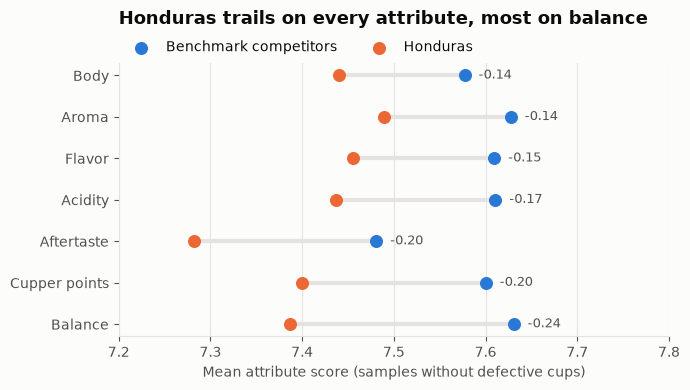

In [35]:
profile = sensory[sensory["subset"] == "no defective cups"].sort_values("gap", ascending=False)
names = profile["attribute"].str.replace("_", " ").str.capitalize()

fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(profile))
ax.hlines(y, profile["honduras"], profile["competitors"], color=GRID, linewidth=3, zorder=1)
ax.scatter(profile["competitors"], y, s=70, color=COLOR_MAIN, label="Benchmark competitors", zorder=3)
ax.scatter(profile["honduras"], y, s=70, color=COLOR_HONDURAS, label="Honduras", zorder=3)
for yi, (comp, gap) in enumerate(zip(profile["competitors"], profile["gap"])):
    ax.annotate(f"{gap:.2f}", (comp, yi), xytext=(10, 0), textcoords="offset points",
                va="center", color=MUTED, fontsize=9)
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlim(7.2, 7.8)
ax.set_xlabel("Mean attribute score (samples without defective cups)")
ax.set_title("Honduras trails on every attribute, most on balance", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, borderaxespad=0.2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "q5_sensory_profile.png", dpi=200)
plt.show()

### 3.6 Extra · Honduras over time

Honduras has enough samples only for 2014–2017 (F27). The competitors' line is the **mean of the 5 country means**, so a country with many samples (Colombia, Guatemala) does not dominate it.

In [36]:
years = df[df["grading_year"].between(2014, 2017)]

competitors_trend = (years[years["country"].isin(BENCHMARK)]
                     .groupby(["grading_year", "country"])["total_cup_points"].mean()
                     .groupby("grading_year").mean())

hn_years = years[years["country"] == "Honduras"]
trend = hn_years.groupby("grading_year")["total_cup_points"].agg(["count", "mean", "std"])
trend["ci95"] = 1.96 * trend["std"] / np.sqrt(trend["count"])
trend["mean_no_defective_cup"] = hn_years[~hn_years["has_defective_cup"]].groupby("grading_year")["total_cup_points"].mean()
trend["competitors"] = competitors_trend
trend["gap"] = trend["mean"] - trend["competitors"]

r, pval = stats.spearmanr(hn_years["grading_year"], hn_years["total_cup_points"])
print(f"Honduras trend: rho = {r:.2f}, p = {pval:.3f}")
no_def = hn_years[~hn_years["has_defective_cup"]]
r, pval = stats.spearmanr(no_def["grading_year"], no_def["total_cup_points"])
print(f"Without defective cups: rho = {r:.2f}, p = {pval:.3f}")
trend.round(2)

Honduras trend: rho = 0.35, p = 0.012
Without defective cups: rho = 0.20, p = 0.188


,count,mean,std,ci95,mean_no_defective_cup,competitors,gap
grading_year,,,,,,,
2014,17,78.71,5.33,2.54,81.74,82.88,-4.18
2015,12,81.24,0.62,0.35,81.24,83.41,-2.18
2016,6,82.18,1.39,1.11,82.18,83.33,-1.15
2017,15,82.40,1.82,0.92,82.40,82.79,-0.39


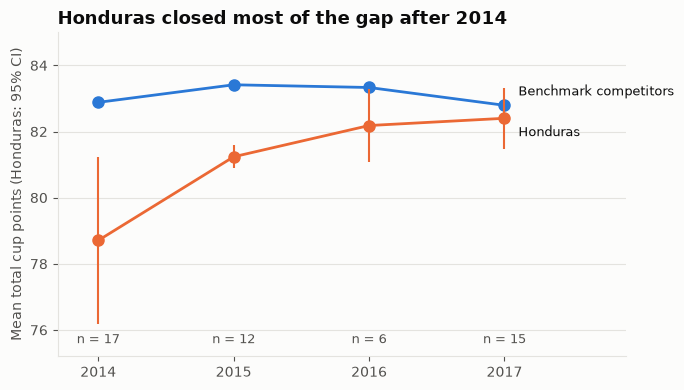

In [37]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(trend.index, trend["competitors"], "o-", color=COLOR_MAIN, linewidth=2, markersize=8)
ax.errorbar(trend.index, trend["mean"], yerr=trend["ci95"], fmt="o-", color=COLOR_HONDURAS,
            linewidth=2, markersize=8, elinewidth=1.5, capsize=0)
for year, n in trend["count"].items():
    ax.annotate(f"n = {n}", (year, 75.6), ha="center", color=MUTED, fontsize=9)
last = trend.index[-1]
ax.annotate("Benchmark competitors", (last, trend.loc[last, "competitors"]), xytext=(10, 10),
            textcoords="offset points", va="center", color=TEXT, fontsize=9)
ax.annotate("Honduras", (last, trend.loc[last, "mean"]), xytext=(10, -10),
            textcoords="offset points", va="center", color=TEXT, fontsize=9)
ax.set_xticks(trend.index)
ax.set_xlim(trend.index[0] - 0.3, last + 0.9)
ax.set_ylim(75.2, 85)
ax.set_ylabel("Mean total cup points (Honduras: 95% CI)")
ax.set_title("Honduras closed most of the gap after 2014")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(VISUALS / "extra_honduras_trend.png", dpi=200)
plt.show()

## 4. Export for Tableau

The dashboard uses two sources:

1. `coffee_arabica_clean.csv` — one row per sample (exported in section 2.4).
2. `coffee_sensory_long.csv` — the 7 quality attributes in **long format** (one row per sample × attribute). Tableau can then draw the sensory profile with `attribute` on one axis and `score` on the other, instead of 7 separate measures.

In [38]:
ATTRIBUTE_LABELS = {a: a.replace("_", " ").capitalize() for a in QUALITY_ATTRIBUTES}

sensory_long = (df.melt(id_vars=["sample_id", "country", "grading_year", "processing_method", "has_defective_cup"],
                        value_vars=QUALITY_ATTRIBUTES, var_name="attribute", value_name="score")
                .assign(attribute=lambda d: d["attribute"].map(ATTRIBUTE_LABELS)))

assert len(sensory_long) == len(df) * len(QUALITY_ATTRIBUTES)
sensory_long.to_csv(DATA_CLEAN / "coffee_sensory_long.csv", index=False)
print(sensory_long.shape)
sensory_long.head()

(9177, 7)


,sample_id,country,grading_year,processing_method,has_defective_cup,attribute,score
0,1,Ethiopia,2015,Washed,False,Aroma,8.67
1,2,Ethiopia,2015,Washed,False,Aroma,8.75
2,3,Guatemala,2010,Unknown,False,Aroma,8.42
3,4,Ethiopia,2015,Natural,False,Aroma,8.17
4,5,Ethiopia,2015,Washed,False,Aroma,8.25
